# Week 6 - Blue Agent: detecting GAN and adversarial faces

The Red Agent (`red_agent/RedAgent_Attacks.ipynb`) produced 2,500 face images in 5 categories. The Blue Agent learns to tell them apart **before** the face-recognition result is trusted.

| class | what it is | why it matters |
|---|---|---|
| `genuine` | real held-out CelebA face | must be accepted |
| `gan` | fake face from our 50-epoch DCGAN | synthetic identity |
| `fgsm` | real face + one-step FGSM noise (8/255) | misidentified, lower confidence |
| `pgd` | real face + 20-step PGD noise (8/255) | misidentified with **0.99 confidence** - confidence alone cannot catch it |
| `gan_adv` | GAN face + FGSM or PGD noise | strongest attack: a fake face turned into a confident match |

**Design choices (approved):**
1. **Model:** ResNet-18 pretrained on ImageNet, last layer replaced with 5 outputs, fine-tuned.
2. **Classes:** the 5 above, plus a **`suspicious`** decision when the top probability is below a threshold picked on the validation set (GP doc: genuine / GAN / FGSM / PGD / suspicious).
3. **Split 70 / 15 / 15 by person:** `genuine`, `fgsm` and `pgd` are made from the *same* 500 faces, so a person and all their attacked copies stay in one split - no leakage. GAN faces belong to nobody and are split per image.
4. **Anti-shortcut:** GAN faces are blurry, so the model could learn "blurry = fake" and reject a real user with a bad camera. During training ~30% of genuine faces are randomly downscaled or blurred and **kept labelled genuine**.
5. **Augmentation:** horizontal flip only. Attack images are never resized, blurred or compressed - that would erase the adversarial noise the model must learn.

Needs (inside `celeba/`): `red_agent_samples/` with `labels.csv` (output of RedAgent_Attacks). Output: `celeba/blue_agent/`.

### 0. setup

In [1]:
import os, time, copy, random, shutil
os.chdir("/workspace")
print("working directory:", os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageFilter
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, roc_auc_score, roc_curve)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")
print("torch", torch.__version__, "| torchvision", torchvision.__version__)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cudnn.benchmark = True

working directory: /workspace
device: cuda | NVIDIA RTX PRO 6000 Blackwell Server Edition MIG 1g.24gb
torch 2.8.0+cu128 | torchvision 0.23.0+cu128


In [2]:
BASE = "./celeba"
SAMPLES_DIR = os.path.join(BASE, "red_agent_samples")
OUT_DIR = os.path.join(BASE, "blue_agent")
os.makedirs(OUT_DIR, exist_ok=True)

CLASSES = ["genuine", "gan", "fgsm", "pgd", "gan_adv"]
CLS_IDX = {c: i for i, c in enumerate(CLASSES)}

EPOCHS = 20
BATCH = 64
LR = 3e-4
WEIGHT_DECAY = 1e-4
DEGRADE_P = 0.3        # share of genuine training faces randomly downscaled/blurred (anti-shortcut)
KEEP_CORRECT = 0.95    # suspicious threshold: keep 95% of correct validation predictions
NUM_WORKERS = min(8, os.cpu_count() or 2)
IMG_SIZE = 160

### 1. load the Red Agent dataset
`labels.csv` has one row per image: `category`, `file_name`, `identity` (-1 for GAN faces) and `attack` (none / fgsm / pgd).

In [3]:
labels = pd.read_csv(os.path.join(SAMPLES_DIR, "labels.csv"))
labels["path"] = [os.path.join(SAMPLES_DIR, c, f) for c, f in zip(labels["category"], labels["file_name"])]
labels["label"] = labels["category"].map(CLS_IDX)
missing = [p for p in labels["path"] if not os.path.exists(p)]
assert not missing, f"{len(missing)} image files missing, e.g. {missing[:3]}"
assert labels["label"].notna().all(), "unknown category in labels.csv"

sizes = {Image.open(p).size for p in labels["path"].sample(min(50, len(labels)), random_state=SEED)}
print("image sizes:", sizes)
print(labels["category"].value_counts().reindex(CLASSES).to_string())

image sizes: {(160, 160)}
category
genuine    500
gan        500
fgsm       500
pgd        500
gan_adv    500


### 2. split 70 / 15 / 15 by person (no leakage)
- `genuine`, `fgsm`, `pgd`: grouped by **identity** - one person's real photos and their attacked copies all go to the same split. A random split would put the FGSM copy of a face in training and its PGD copy in testing, and the test score would be inflated.
- `gan`, `gan_adv`: each image is its own face (and `gan_adv` uses different GAN faces than `gan`), so they are split per image, per class.

In [4]:
rng = np.random.default_rng(SEED)

def cut(n):
    n_tr = int(round(0.70 * n)); n_va = int(round(0.15 * n))
    return np.array(["train"] * n_tr + ["val"] * n_va + ["test"] * (n - n_tr - n_va))

labels["split"] = ""
person = labels["category"].isin(["genuine", "fgsm", "pgd"])

ids = rng.permutation(np.array(sorted(labels.loc[person, "identity"].unique())))
id_split = dict(zip(ids, cut(len(ids))))
labels.loc[person, "split"] = labels.loc[person, "identity"].map(id_split)

for cat in ["gan", "gan_adv"]:
    idx = rng.permutation(labels.index[labels["category"] == cat].to_numpy())
    labels.loc[idx, "split"] = cut(len(idx))

# leakage checks
per_id = labels[person].groupby("identity")["split"].nunique()
assert (per_id == 1).all(), "an identity appears in more than one split"
per_file = labels[person].groupby("file_name")["split"].nunique()
assert (per_file == 1).all(), "a source face appears in more than one split"
print("leakage check passed: every person and every source face is in exactly one split\n")

print(pd.crosstab(labels["category"], labels["split"]).reindex(index=CLASSES, columns=["train", "val", "test"]).to_string())
labels[["category", "file_name", "identity", "attack", "split"]].to_csv(os.path.join(OUT_DIR, "split.csv"), index=False)

leakage check passed: every person and every source face is in exactly one split

split     train  val  test
category                  
genuine     355   72    73
gan         350   75    75
fgsm        355   72    73
pgd         355   72    73
gan_adv     350   75    75


### 3. dataset, augmentation and the anti-shortcut trick
- images are used at their saved 160x160 PNG resolution - **no resize**, so the 8/255 adversarial noise is untouched.
- training only: horizontal flip for every class; for ~30% of **genuine** faces, either downscale to 64x64 and back (the same resolution loss our GAN faces have) or a light Gaussian blur. They stay labelled `genuine`, so "blurry" alone can no longer mean "fake".
- normalised with the ImageNet mean/std, because the backbone was pretrained on ImageNet.

train 1765 | val 366 | test 369


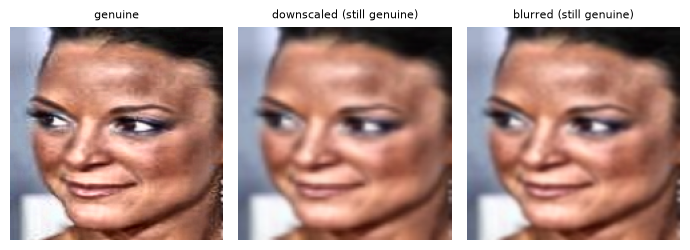

In [5]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def to_tensor(img):
    a = torch.from_numpy(np.asarray(img, dtype=np.float32) / 255.0).permute(2, 0, 1)
    return (a - MEAN) / STD

def degrade(img, mode=None, radius=None):
    # mode "down": 160 -> 64 -> 160 (GAN-like resolution loss); mode "blur": Gaussian blur
    mode = mode or random.choice(["down", "blur"])
    if mode == "down":
        return img.resize((64, 64), Image.BILINEAR).resize(img.size, Image.BILINEAR)
    return img.filter(ImageFilter.GaussianBlur(radius if radius is not None else random.uniform(0.6, 1.5)))

class FaceSet(Dataset):
    def __init__(self, df, train=False):
        self.paths = df["path"].tolist()
        self.labels = df["label"].astype(int).tolist()
        self.train = train

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        y = self.labels[i]
        if self.train:
            if y == CLS_IDX["genuine"] and random.random() < DEGRADE_P:
                img = degrade(img)
            if random.random() < 0.5:
                img = img.transpose(Image.FLIP_LEFT_RIGHT)
        return to_tensor(img), y

df_tr, df_va, df_te = (labels[labels["split"] == s].reset_index(drop=True) for s in ["train", "val", "test"])
loader_kw = dict(batch_size=BATCH, num_workers=NUM_WORKERS, pin_memory=device.type == "cuda")
dl_tr = DataLoader(FaceSet(df_tr, train=True), shuffle=True, drop_last=False, **loader_kw)
dl_va = DataLoader(FaceSet(df_va), shuffle=False, **loader_kw)
dl_te = DataLoader(FaceSet(df_te), shuffle=False, **loader_kw)
print(f"train {len(df_tr)} | val {len(df_va)} | test {len(df_te)}")

# what the anti-shortcut augmentation looks like
ex = Image.open(df_tr[df_tr["category"] == "genuine"]["path"].iloc[0]).convert("RGB")
fig, ax = plt.subplots(1, 3, figsize=(7, 2.6))
for a, (t, im) in zip(ax, [("genuine", ex), ("downscaled (still genuine)", degrade(ex, "down")),
                           ("blurred (still genuine)", degrade(ex, "blur", 1.2))]):
    a.imshow(im); a.set_title(t, fontsize=8); a.axis("off")
plt.tight_layout(); plt.show()

### 4. model: ResNet-18 pretrained on ImageNet
ImageNet pretraining gives the network ready-made edge and texture filters, which matters with only ~1,750 training images. The 1000-class ImageNet layer is replaced with a 5-class layer; the whole network is then fine-tuned.

In [6]:
model = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
model.fc = nn.Linear(model.fc.in_features, len(CLASSES))
model = model.to(device)
print(f"ResNet-18 | parameters: {sum(p.numel() for p in model.parameters()):,} | outputs: {CLASSES}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 107MB/s] 


ResNet-18 | parameters: 11,179,077 | outputs: ['genuine', 'gan', 'fgsm', 'pgd', 'gan_adv']


### 5. training
AdamW + cosine learning-rate decay, cross-entropy loss (classes are balanced, 500 each). After every epoch the model is scored on the **validation** set; the epoch with the best validation macro-F1 is kept. The test set is not touched until section 7.

In [7]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

@torch.no_grad()
def predict_loader(dl):
    model.eval()
    probs, ys, loss_sum = [], [], 0.0
    for x, y in dl:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        out = model(x)
        loss_sum += criterion(out, y).item() * len(y)
        probs.append(torch.softmax(out, 1).cpu()); ys.append(y.cpu())
    probs, ys = torch.cat(probs).numpy(), torch.cat(ys).numpy()
    return probs, ys, loss_sum / len(ys)

history, best_f1, best_state, best_epoch = [], -1.0, None, 0
t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    tr_loss, tr_correct, n = 0.0, 0, 0
    for x, y in dl_tr:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        tr_loss += loss.item() * len(y); tr_correct += (out.argmax(1) == y).sum().item(); n += len(y)
    scheduler.step()

    p_va, y_va, va_loss = predict_loader(dl_va)
    va_pred = p_va.argmax(1)
    va_acc, va_f1 = accuracy_score(y_va, va_pred), f1_score(y_va, va_pred, average="macro")
    history.append(dict(epoch=epoch, train_loss=tr_loss / n, train_acc=tr_correct / n,
                        val_loss=va_loss, val_acc=va_acc, val_macro_f1=va_f1))
    mark = ""
    if va_f1 > best_f1:
        best_f1, best_epoch, best_state = va_f1, epoch, copy.deepcopy(model.state_dict()); mark = "  <- best"
    print(f"epoch {epoch:2d}/{EPOCHS} | train loss {tr_loss / n:.3f} acc {tr_correct / n:.3f} | "
          f"val loss {va_loss:.3f} acc {va_acc:.3f} macro-F1 {va_f1:.3f}{mark}")

model.load_state_dict(best_state)
print(f"\ntraining done in {time.time() - t0:.0f}s | best epoch {best_epoch} (val macro-F1 {best_f1:.3f})")
hist = pd.DataFrame(history)
hist.to_csv(os.path.join(OUT_DIR, "history.csv"), index=False)

epoch  1/20 | train loss 0.362 acc 0.859 | val loss 0.030 acc 0.989 macro-F1 0.989  <- best
epoch  2/20 | train loss 0.097 acc 0.963 | val loss 0.125 acc 0.956 macro-F1 0.956
epoch  3/20 | train loss 0.057 acc 0.982 | val loss 0.232 acc 0.918 macro-F1 0.913
epoch  4/20 | train loss 0.032 acc 0.992 | val loss 0.023 acc 0.992 macro-F1 0.992  <- best
epoch  5/20 | train loss 0.017 acc 0.994 | val loss 0.081 acc 0.973 macro-F1 0.973
epoch  6/20 | train loss 0.052 acc 0.984 | val loss 0.104 acc 0.962 macro-F1 0.962
epoch  7/20 | train loss 0.016 acc 0.995 | val loss 0.007 acc 0.997 macro-F1 0.997  <- best
epoch  8/20 | train loss 0.016 acc 0.995 | val loss 0.108 acc 0.962 macro-F1 0.962
epoch  9/20 | train loss 0.004 acc 0.999 | val loss 0.006 acc 1.000 macro-F1 1.000  <- best
epoch 10/20 | train loss 0.008 acc 0.999 | val loss 0.042 acc 0.978 macro-F1 0.978
epoch 11/20 | train loss 0.007 acc 0.997 | val loss 0.001 acc 1.000 macro-F1 1.000
epoch 12/20 | train loss 0.005 acc 0.999 | val loss

### 6. training curves (overfitting check)
Train accuracy near 1.0 with validation clearly lower and validation loss rising = overfitting. The saved model is the best-validation epoch, not the last one.

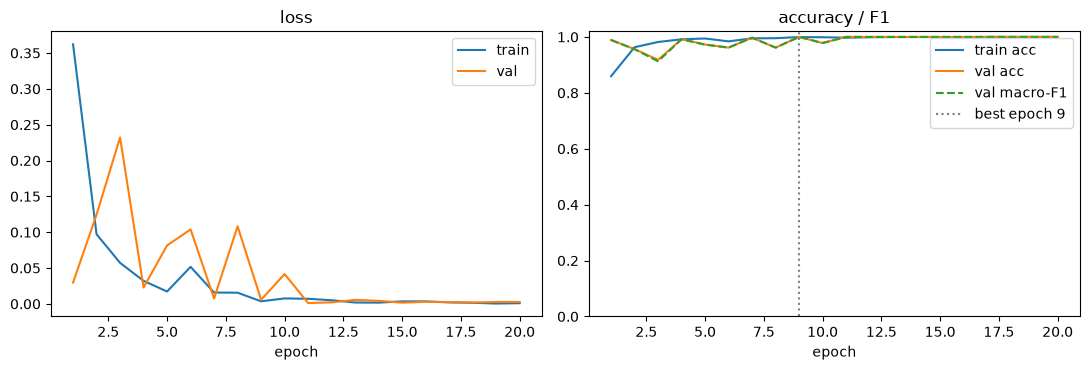

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(hist["epoch"], hist["train_loss"], label="train"); ax[0].plot(hist["epoch"], hist["val_loss"], label="val")
ax[0].set_title("loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(hist["epoch"], hist["train_acc"], label="train acc"); ax[1].plot(hist["epoch"], hist["val_acc"], label="val acc")
ax[1].plot(hist["epoch"], hist["val_macro_f1"], "--", label="val macro-F1")
ax[1].axvline(best_epoch, color="gray", ls=":", label=f"best epoch {best_epoch}")
ax[1].set_title("accuracy / F1"); ax[1].set_xlabel("epoch"); ax[1].set_ylim(0, 1.02); ax[1].legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "training_curves.png"), dpi=120); plt.show()

### 7. test results (images never seen in training or model selection)
- **precision**: when the Blue Agent says "PGD", how often is it really PGD
- **recall**: of all real PGD images, how many it caught
- **F1**: balance of the two

TEST accuracy: 0.992 | macro-F1: 0.992 | images: 369

              precision    recall  f1-score   support

     genuine      1.000     1.000     1.000        73
         gan      1.000     1.000     1.000        75
        fgsm      0.986     0.986     0.986        73
         pgd      1.000     0.973     0.986        73
     gan_adv      0.974     1.000     0.987        75

    accuracy                          0.992       369
   macro avg      0.992     0.992     0.992       369
weighted avg      0.992     0.992     0.992       369



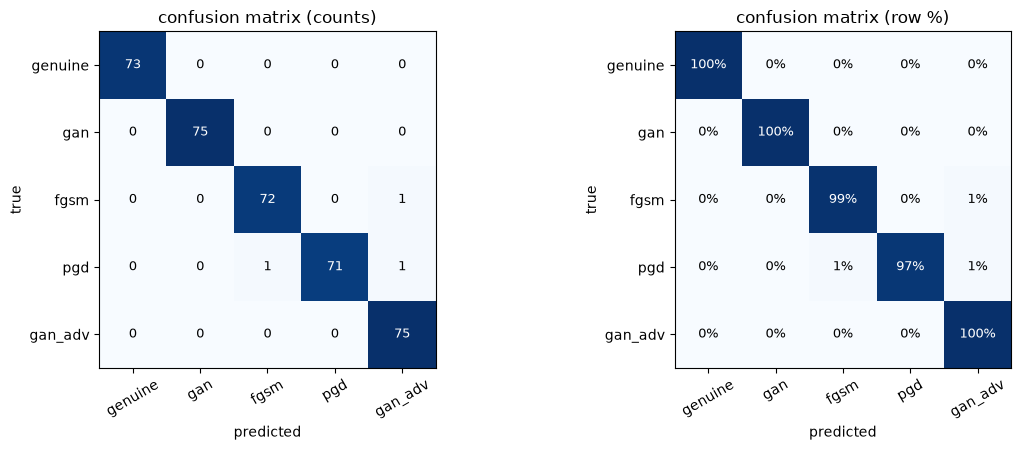

In [9]:
p_te, y_te, te_loss = predict_loader(dl_te)
pred_te = p_te.argmax(1)
test_acc = accuracy_score(y_te, pred_te)
test_f1 = f1_score(y_te, pred_te, average="macro")
print(f"TEST accuracy: {test_acc:.3f} | macro-F1: {test_f1:.3f} | images: {len(y_te)}\n")
report = classification_report(y_te, pred_te, labels=range(len(CLASSES)), target_names=CLASSES, digits=3, zero_division=0)
print(report)

cm = confusion_matrix(y_te, pred_te, labels=range(len(CLASSES)))
cm_norm = cm / cm.sum(1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for a, m, title, fmt in [(ax[0], cm, "confusion matrix (counts)", "d"), (ax[1], cm_norm, "confusion matrix (row %)", ".0%")]:
    a.imshow(m, cmap="Blues")
    a.set_xticks(range(len(CLASSES)), CLASSES, rotation=30); a.set_yticks(range(len(CLASSES)), CLASSES)
    a.set_xlabel("predicted"); a.set_ylabel("true"); a.set_title(title)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            v = m[i, j]
            a.text(j, i, format(v, fmt), ha="center", va="center", fontsize=9,
                   color="white" if (cm_norm[i, j] > 0.5) else "black")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "confusion_matrix.png"), dpi=120); plt.show()

### 8. genuine vs attack - the number the risk engine needs
The risk engine does not need to know *which* attack it is, only *how likely the image is manipulated*:

`attack probability = 1 - P(genuine)`

- **ROC AUC**: 1.0 = attacks and genuine faces perfectly separated, 0.5 = guessing.
- at the default cut-off (attack probability >= 0.5): how many of each attack type are caught, and how many genuine users are wrongly flagged (false alarms).

genuine vs attack ROC AUC: 1.0000
(for genuine, 'flagged_as_attack' = false-alarm rate; for the others it is the detection rate)

        category  images flagged_as_attack  mean_attack_prob
         genuine      73              0.0%             0.003
             gan      75            100.0%             0.998
            fgsm      73            100.0%             1.000
             pgd      73            100.0%             1.000
         gan_adv      75            100.0%             1.000
  gan_adv (fgsm)      33            100.0%             1.000
   gan_adv (pgd)      42            100.0%             1.000


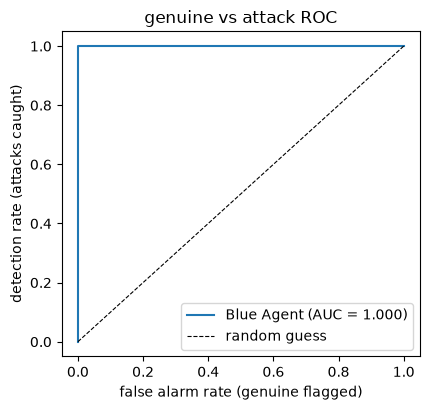

In [10]:
p_attack = 1 - p_te[:, CLS_IDX["genuine"]]
is_attack = (y_te != CLS_IDX["genuine"]).astype(int)
auc = roc_auc_score(is_attack, p_attack) if len(np.unique(is_attack)) == 2 else float("nan")
flag = p_attack >= 0.5

rows = []
for cat in CLASSES:
    m = (df_te["category"] == cat).to_numpy()
    rows.append(dict(category=cat, images=int(m.sum()),
                     flagged_as_attack=f"{flag[m].mean():.1%}" if m.any() else "-",
                     mean_attack_prob=round(float(p_attack[m].mean()), 3) if m.any() else np.nan))
for att in ["fgsm", "pgd"]:
    m = ((df_te["category"] == "gan_adv") & (df_te["attack"] == att)).to_numpy()
    rows.append(dict(category=f"  gan_adv ({att})", images=int(m.sum()),
                     flagged_as_attack=f"{flag[m].mean():.1%}" if m.any() else "-",
                     mean_attack_prob=round(float(p_attack[m].mean()), 3) if m.any() else np.nan))
det = pd.DataFrame(rows)
print(f"genuine vs attack ROC AUC: {auc:.4f}")
print("(for genuine, 'flagged_as_attack' = false-alarm rate; for the others it is the detection rate)\n")
print(det.to_string(index=False))

fpr, tpr, _ = roc_curve(is_attack, p_attack)
plt.figure(figsize=(4.4, 4.2))
plt.plot(fpr, tpr, label=f"Blue Agent (AUC = {auc:.3f})"); plt.plot([0, 1], [0, 1], "k--", lw=0.8, label="random guess")
plt.xlabel("false alarm rate (genuine flagged)"); plt.ylabel("detection rate (attacks caught)")
plt.title("genuine vs attack ROC"); plt.legend(loc="lower right")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "roc_genuine_vs_attack.png"), dpi=120); plt.show()

### 9. the `suspicious` decision
When the Blue Agent is not sure (top probability below a threshold) it answers **`suspicious`** instead of guessing a class - the risk engine can then send the attempt to extra checks or the honeypot.

The threshold is picked on the **validation** set: the value that still keeps 95% of the correct validation predictions. It is then applied unchanged to the test set.

In [11]:
p_va, y_va, _ = predict_loader(dl_va)
conf_va = p_va.max(1)
correct_va = p_va.argmax(1) == y_va
THRESHOLD = float(np.quantile(conf_va[correct_va], 1 - KEEP_CORRECT)) if correct_va.any() else 0.5
print(f"suspicious threshold (from validation): {THRESHOLD:.3f}")

def decide(probs, threshold=THRESHOLD):
    probs = np.asarray(probs)
    return np.where(probs.max(-1) < threshold, "suspicious", np.array(CLASSES)[probs.argmax(-1)])

conf_te = p_te.max(1)
susp = conf_te < THRESHOLD
wrong = pred_te != y_te
print(f"test images marked suspicious: {susp.sum()} / {len(susp)} ({susp.mean():.1%})")
print(f"accuracy on the confident (not suspicious) test images: {accuracy_score(y_te[~susp], pred_te[~susp]):.3f}"
      if (~susp).any() else "all test images suspicious")
print(f"share of the model's mistakes that were caught as suspicious: {susp[wrong].mean():.1%}" if wrong.any() else "no mistakes on the test set")
print("\nsuspicious per true class:")
print(pd.Series(susp, index=df_te["category"]).groupby(level=0).mean().reindex(CLASSES).map("{:.1%}".format).to_string())

suspicious threshold (from validation): 0.990
test images marked suspicious: 21 / 369 (5.7%)
accuracy on the confident (not suspicious) test images: 1.000
share of the model's mistakes that were caught as suspicious: 100.0%

suspicious per true class:
category
genuine    2.7%
gan        8.0%
fgsm       6.8%
pgd        9.6%
gan_adv    1.3%


### 10. shortcut test: is "blurry" being treated as "fake"?
Take the **test** genuine faces (never seen in training), downscale or blur them, and check what the Blue Agent says. A good model still calls most of them `genuine`; a model that learned the shortcut would call them `gan`.

In [12]:
gen_te = df_te[df_te["category"] == "genuine"]

@torch.no_grad()
def predict_images(imgs):
    model.eval()
    out = []
    for i in range(0, len(imgs), BATCH):
        x = torch.stack([to_tensor(im) for im in imgs[i:i + BATCH]]).to(device)
        out.append(torch.softmax(model(x), 1).cpu())
    return torch.cat(out).numpy()

clean = [Image.open(p).convert("RGB") for p in gen_te["path"]]
variants = {"clean": clean,
            "downscaled 160->64->160": [degrade(im, "down") for im in clean],
            "blur radius 1.0": [degrade(im, "blur", 1.0) for im in clean],
            "blur radius 2.0 (stronger than training)": [degrade(im, "blur", 2.0) for im in clean]}
rows = []
for name, imgs in variants.items():
    pr = predict_images(imgs); pc = pr.argmax(1)
    rows.append({"genuine test faces": name, "called genuine": f"{(pc == 0).mean():.1%}",
                 "called gan": f"{(pc == CLS_IDX['gan']).mean():.1%}",
                 "mean attack prob": round(float((1 - pr[:, 0]).mean()), 3)})
shortcut = pd.DataFrame(rows)
print(shortcut.to_string(index=False))

                      genuine test faces called genuine called gan  mean attack prob
                                   clean         100.0%       0.0%             0.003
                 downscaled 160->64->160          98.6%       1.4%             0.021
                         blur radius 1.0          98.6%       1.4%             0.009
blur radius 2.0 (stronger than training)          93.2%       6.8%             0.086


### 11. mistakes - which test images fooled the Blue Agent

3 misclassified test images
fgsm -> gan_adv    1
pgd -> gan_adv     1
pgd -> fgsm        1


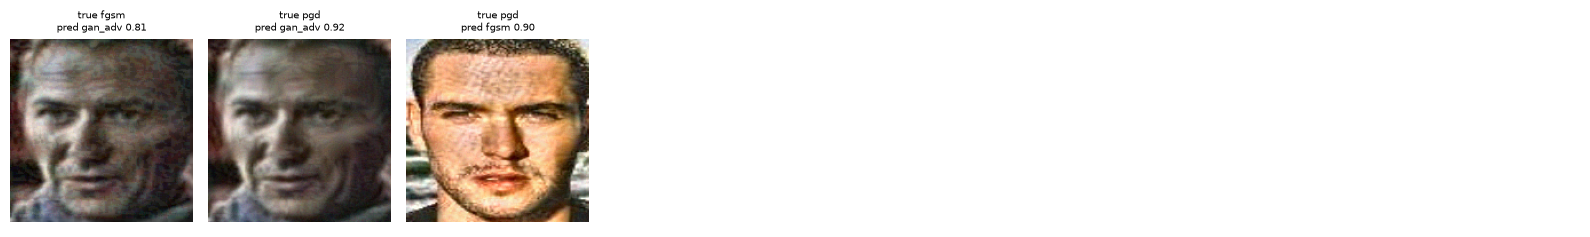

In [13]:
wrong_idx = np.where(pred_te != y_te)[0]
print(f"{len(wrong_idx)} misclassified test images")
pairs = pd.Series([f"{CLASSES[t]} -> {CLASSES[p]}" for t, p in zip(y_te[wrong_idx], pred_te[wrong_idx])]).value_counts()
print(pairs.to_string() if len(pairs) else "")
show = wrong_idx[:16]
if len(show):
    cols = 8; rws = int(np.ceil(len(show) / cols))
    fig, axes = plt.subplots(rws, cols, figsize=(2 * cols, 2.3 * rws), squeeze=False)
    for a in axes.ravel():
        a.axis("off")
    for a, k in zip(axes.ravel(), show):
        a.imshow(Image.open(df_te["path"].iloc[k]))
        a.set_title(f"true {CLASSES[y_te[k]]}\npred {CLASSES[pred_te[k]]} {p_te[k].max():.2f}", fontsize=7)
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "mistakes.png"), dpi=110); plt.show()

### 12. save everything
`celeba/blue_agent/`: the model (with class names, threshold and normalisation, so the backend can load it without this notebook), `split.csv`, `history.csv`, `metrics.csv`, `detection_by_category.csv`, `shortcut_test.csv` and the figures - plus one zip for download.

In [14]:
MODEL_PATH = os.path.join(OUT_DIR, "blue_agent_resnet18.pth")
torch.save({"arch": "resnet18", "state_dict": model.state_dict(), "classes": CLASSES,
            "threshold": THRESHOLD, "input_size": IMG_SIZE,
            "mean": MEAN.flatten().tolist(), "std": STD.flatten().tolist(),
            "best_epoch": best_epoch, "seed": SEED}, MODEL_PATH)

rep = classification_report(y_te, pred_te, labels=range(len(CLASSES)), target_names=CLASSES, output_dict=True, zero_division=0)
metrics = pd.DataFrame([{"class": c, "precision": rep[c]["precision"], "recall": rep[c]["recall"],
                         "f1": rep[c]["f1-score"], "test_images": int(rep[c]["support"])} for c in CLASSES])
metrics.loc[len(metrics)] = {"class": "OVERALL (accuracy / macro-F1 / AUC)", "precision": test_acc,
                             "recall": test_f1, "f1": auc, "test_images": len(y_te)}
metrics.round(4).to_csv(os.path.join(OUT_DIR, "metrics.csv"), index=False)
det.to_csv(os.path.join(OUT_DIR, "detection_by_category.csv"), index=False)
shortcut.to_csv(os.path.join(OUT_DIR, "shortcut_test.csv"), index=False)

zip_path = shutil.make_archive(os.path.join(BASE, "blue_agent_results"), "zip", OUT_DIR)
print("saved:", sorted(os.listdir(OUT_DIR)))
print("zip:", zip_path, f"({os.path.getsize(zip_path) / 1e6:.0f} MB)")

saved: ['blue_agent_resnet18.pth', 'confusion_matrix.png', 'detection_by_category.csv', 'history.csv', 'metrics.csv', 'mistakes.png', 'roc_genuine_vs_attack.png', 'shortcut_test.csv', 'split.csv', 'training_curves.png']
zip: /workspace/celeba/blue_agent_results.zip (42 MB)


### 13. `predict()` - one image in, a decision out
This is the function the backend and risk engine will call. It takes an image (file path or PIL image, ideally the 160x160 MTCNN crop the face-recognition pipeline already produces) and returns the 5 class probabilities, the attack probability and the decision (a class name or `suspicious`).

In [15]:
def load_blue_agent(path=MODEL_PATH, map_location=device):
    ckpt = torch.load(path, map_location=map_location, weights_only=True)   # tensors + plain values only: no pickle code execution
    net = torchvision.models.resnet18(weights=None)
    net.fc = nn.Linear(net.fc.in_features, len(ckpt["classes"]))
    net.load_state_dict(ckpt["state_dict"])
    return net.to(map_location).eval(), ckpt

@torch.no_grad()
def predict(image, net=None, ckpt=None):
    net, ckpt = (net, ckpt) if net is not None else (model.eval(), {"classes": CLASSES, "threshold": THRESHOLD, "input_size": IMG_SIZE})
    img = Image.open(image).convert("RGB") if isinstance(image, (str, os.PathLike)) else image.convert("RGB")
    s = ckpt["input_size"]
    if img.size != (s, s):
        img = img.resize((s, s), Image.BILINEAR)      # resizing weakens adversarial noise - pass 160x160 crops when possible
    probs = torch.softmax(net(to_tensor(img).unsqueeze(0).to(device)), 1)[0].cpu().numpy()
    top = int(probs.argmax())
    return {"decision": "suspicious" if probs[top] < ckpt["threshold"] else ckpt["classes"][top],
            "confidence": round(float(probs[top]), 4),
            "attack_probability": round(float(1 - probs[0]), 4),
            "probabilities": {c: round(float(p), 4) for c, p in zip(ckpt["classes"], probs)}}

# demo: reload the saved model from disk and run it on one test image per class
net, ckpt = load_blue_agent()
for cat in CLASSES:
    sample = df_te[df_te["category"] == cat]
    if len(sample):
        r = predict(sample["path"].iloc[0], net, ckpt)
        print(f"{cat:8s} -> {r['decision']:10s} conf {r['confidence']:.3f} | attack prob {r['attack_probability']:.3f}")

genuine  -> genuine    conf 1.000 | attack prob 0.000
gan      -> gan        conf 1.000 | attack prob 1.000
fgsm     -> fgsm       conf 1.000 | attack prob 1.000
pgd      -> pgd        conf 1.000 | attack prob 1.000
gan_adv  -> gan_adv    conf 1.000 | attack prob 1.000


### milestone check
- Blue Agent trained on the 5 Red Agent categories with a **person-level split** (no leakage)
- test accuracy, per-class precision / recall / F1 and the confusion matrix reported (section 7)
- **genuine vs attack ROC AUC** reported - the manipulation probability the risk engine will use (section 8)
- `suspicious` decision with a validation-picked threshold (section 9)
- shortcut test shows whether blurry real faces are wrongly called fake (section 10)
- `celeba/blue_agent_results.zip` holds the model, metrics and figures for download
- next: risk engine combines face-recognition confidence + attack probability + input quality into one risk score